# Proyecto Final de Econometría

**Nombre:** Israel Isaías Orta Reyna  
**Matrícula:** A01452204  
**Materia:** Econometría  
**Profesor:** Raymundo Díaz Robles

## 1. Objetivo del proyecto

En este proyecto busco aplicar de  forma práctica diferentes herramientas de econometría al análisis de un portafolio de acciones.

A lo largo del trabajo analizaré el comportamiento de distintas emisoras utilizando modelos de regresión, datos de panel y modelos de series de tiempo como AR, ARMA, ARIMA y GARCH. También buscaré generar pronósticos de corto plazo y evaluar variables relacionadas con el riesgo y la construcción del portafolio.

Finalmente, tomaré los resultados del análisis como base para definir una estrategia de trading y la probaré en plataformas de paper trading. Con esto busco llevar el análisis econométrico a una aplicación más práctica, enfocada en la toma de decisiones de inversión.

## 2. Selección de las acciones

Para el desarrollo del proyecto seleccioné un portafolio de 10 acciones de empresas que pertenecen a distintos sectores y que además cuentan con suficiente información histórica para realizar los análisis econométricos.

Las emisoras seleccionadas son:

- Apple Inc. (AAPL)
- Microsoft Corp. (MSFT)
- Alphabet Inc. (GOOGL)
- Meta Platforms Inc. (META)
- NVIDIA Corp. (NVDA)
- Amazon.com Inc. (AMZN)
- JPMorgan Chase & Co. (JPM)
- Bank of America Corp. (BAC)
- Exxon Mobil Corp. (XOM)
- Chevron Corp. (CVX)

La selección busca combinar empresas de tecnología, servicios financieros y energía, con el objetivo de trabajar con un portafolio diversificado y facilitar la comparación de comportamientos entre sectores.


## 3. Preparación de la información

Para realizar los análisis utilicé información histórica de precios de las acciones seleccionadas obtenida de Refinitiv. A partir de estos datos trabajaré con precios de cierre y rendimientos, que posteriormente utilizaré en los modelos de regresión, series de tiempo y análisis del portafolio.

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np

# Cargar archivo con los datos históricos
uploaded = files.upload()

Saving Datos Finales Proyecto Econometria.xlsx to Datos Finales Proyecto Econometria.xlsx


In [ ]:
# Leer el archivo de Excel
df = pd.read_excel("Datos Finales Proyecto Econometria.xlsx")

# Limpiar nombres de columnas por si existe algún espacio extra
df.columns = df.columns.str.strip()

# Convertir la columna de fecha al formato correcto
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

# Mostrar dimensiones, columnas y primeras filas
print("Dimensiones:", df.shape)
print("\nColumnas:")
print(df.columns.tolist())

df.head()

Dimensiones: (1000, 11)

Columnas:
['Date', 'AAPL.O', 'MSFT.O', 'GOOGL.O', 'META.O', 'NVDA.O', 'AMZN.O', 'JPM', 'BAC', 'XOM', 'CVX']


,Date,AAPL.O,MSFT.O,GOOGL.O,META.O,NVDA.O,AMZN.O,JPM,BAC,XOM,CVX
0,2022-11-11,149.70,247.11,96.41,113.02,16.327,100.79,135.30,38.41,113.95,186.46
1,2022-11-14,148.28,241.55,95.70,114.22,16.295,98.49,133.91,37.76,113.37,186.55
2,2022-11-15,150.04,241.97,98.44,117.08,16.666,98.94,132.94,37.70,114.13,188.05
3,2022-11-16,148.79,241.73,98.85,113.23,15.910,97.12,133.12,37.36,112.91,184.99
4,2022-11-17,150.72,241.68,98.36,111.45,15.677,94.85,132.54,37.17,113.06,184.09


In [ ]:
# Calcular rendimientos logarítmicos diarios
precios = df.set_index("Date")

rendimientos = np.log(precios / precios.shift(1))

# Eliminar la primera fila vacía generada por el cálculo
rendimientos = rendimientos.dropna()

print("Dimensiones de rendimientos:", rendimientos.shape)
rendimientos.head()

Dimensiones de rendimientos: (999, 10)


,AAPL.O,MSFT.O,GOOGL.O,META.O,NVDA.O,AMZN.O,JPM,BAC,XOM,CVX
Date,,,,,,,,,,
2022-11-14,-0.009531,-0.022757,-0.007392,0.010562,-0.001962,-0.023084,-0.010327,-0.017068,-0.005103,0.000483
2022-11-15,0.011800,0.001737,0.028229,0.024731,0.022512,0.004559,-0.007270,-0.001590,0.006681,0.008009
2022-11-16,-0.008366,-0.000992,0.004156,-0.033436,-0.046423,-0.018566,0.001353,-0.009059,-0.010747,-0.016406
2022-11-17,0.012888,-0.000207,-0.004969,-0.015845,-0.014753,-0.023651,-0.004366,-0.005099,0.001328,-0.004877
2022-11-18,0.003775,-0.001905,-0.009500,0.005369,-0.017243,-0.007514,0.009761,0.000538,-0.008706,-0.005993


## 4. Análisis descriptivo y correlaciones

En esta sección analizaré de forma general el comportamiento de los rendimientos de las acciones seleccionadas. Primero revisaré algunas estadísticas básicas y después observaré qué tan relacionadas están entre sí mediante una matriz de correlaciones.

In [ ]:
# Estadísticas descriptivas de los rendimientos
estadisticas = rendimientos.describe().T

estadisticas["Media diaria"] = rendimientos.mean()
estadisticas["Volatilidad diaria"] = rendimientos.std()

estadisticas

,count,mean,std,min,25%,50%,75%,max,Media diaria,Volatilidad diaria
AAPL.O,999.0,0.000828,0.016313,-0.097013,-0.007282,0.001172,0.009013,0.142617,0.000828,0.016313
MSFT.O,999.0,0.000765,0.016605,-0.105284,-0.007562,0.000869,0.009347,0.144159,0.000765,0.016605
GOOGL.O,999.0,0.001084,0.019659,-0.135146,-0.009890,0.001614,0.011441,0.097348,0.001084,0.019659
META.O,999.0,0.001688,0.024516,-0.120302,-0.010783,0.001226,0.012981,0.209307,0.001688,0.024516
NVDA.O,999.0,0.002439,0.030063,-0.185946,-0.014571,0.002586,0.019542,0.218088,0.002439,0.030063
AMZN.O,999.0,0.000946,0.020504,-0.094081,-0.010831,0.000423,0.013117,0.142546,0.000946,0.020504
JPM,999.0,0.000906,0.014400,-0.083927,-0.005892,0.001705,0.008686,0.109254,0.000906,0.014400
BAC,999.0,0.000252,0.015824,-0.117246,-0.007791,0.000654,0.008553,0.080924,0.000252,0.015824
XOM,999.0,0.000376,0.015217,-0.074676,-0.008504,0.000583,0.009847,0.057326,0.000376,0.015217
CVX,999.0,0.000131,0.014685,-0.085824,-0.007761,0.000941,0.008899,0.064342,0.000131,0.014685


In [ ]:
# Matriz de correlaciones de los rendimientos
correlaciones = rendimientos.corr()

correlaciones

,AAPL.O,MSFT.O,GOOGL.O,META.O,NVDA.O,AMZN.O,JPM,BAC,XOM,CVX
AAPL.O,1.000000,0.397212,0.383017,0.356113,0.330458,0.379950,0.291154,0.314845,0.123664,0.160153
MSFT.O,0.397212,1.000000,0.407816,0.453259,0.460073,0.558459,0.219399,0.221018,-0.033129,0.043216
GOOGL.O,0.383017,0.407816,1.000000,0.446920,0.373993,0.582666,0.228740,0.226354,-0.049698,0.015478
META.O,0.356113,0.453259,0.446920,1.000000,0.428711,0.562358,0.250222,0.272600,-0.024432,0.028871
NVDA.O,0.330458,0.460073,0.373993,0.428711,1.000000,0.432642,0.249620,0.201739,-0.019012,0.046555
AMZN.O,0.379950,0.558459,0.582666,0.562358,0.432642,1.000000,0.291884,0.303163,-0.031896,0.052071
JPM,0.291154,0.219399,0.228740,0.250222,0.249620,0.291884,1.000000,0.748223,0.233249,0.295427
BAC,0.314845,0.221018,0.226354,0.272600,0.201739,0.303163,0.748223,1.000000,0.257144,0.302399
XOM,0.123664,-0.033129,-0.049698,-0.024432,-0.019012,-0.031896,0.233249,0.257144,1.000000,0.828131
CVX,0.160153,0.043216,0.015478,0.028871,0.046555,0.052071,0.295427,0.302399,0.828131,1.000000


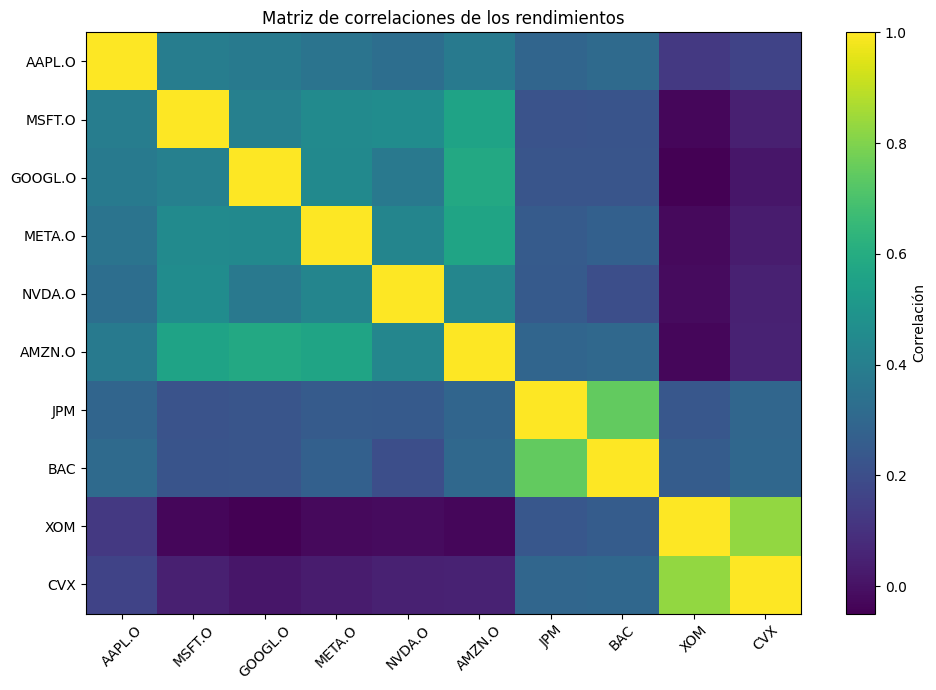

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))
plt.imshow(correlaciones, aspect='auto')

plt.xticks(range(len(correlaciones.columns)), correlaciones.columns, rotation=45)
plt.yticks(range(len(correlaciones.index)), correlaciones.index)

plt.colorbar(label="Correlación")
plt.title("Matriz de correlaciones de los rendimientos")

plt.tight_layout()
plt.show()

Al revisar la matriz de correlaciones se puede notar que algunas acciones del mismo sector suelen moverse de forma parecida. Esto se ve claramente en JPM y BAC, y también en XOM y CVX, donde la relación entre sus rendimientos es relativamente alta.

Por otro lado, las empresas de energía muestran una relación mucho menor con varias de las acciones tecnológicas. Para el portafolio, esto es útil porque combinar empresas de distintos sectores puede ayudar a que no todas reaccionen de la misma forma ante los movimientos del mercado.

## 5. Regresión simple: relación entre Apple y Microsoft
Para revisar la relación entre dos de las acciones del portafolio, tomé los rendimientos diarios de Apple y Microsoft. En este caso utilicé a Apple como la variable que quiero explicar y a Microsoft como referencia para observar qué tan relacionada está una acción con la otra.

Los resultados muestran una relación positiva entre ambas acciones. El coeficiente de Microsoft fue de aproximadamente 0.39, lo que indica que cuando el rendimiento de Microsoft cambia 1%, el rendimiento de Apple tiende a cambiar alrededor de 0.39% en la misma dirección.

El R² fue de 0.158, por lo que Microsoft explica cerca del 15.8% de los movimientos diarios de Apple. Aunque la relación es estadísticamente significativa, también queda claro que una sola acción no es suficiente para explicar completamente el comportamiento de Apple.


In [ ]:
import statsmodels.api as sm

# Rendimientos de Apple y Microsoft
apple = rendimientos["AAPL.O"]
microsoft = rendimientos[["MSFT.O"]]

# Agrego la constante para estimar la regresión
microsoft = sm.add_constant(microsoft)

# Modelo de regresión
regresion_apple_msft = sm.OLS(apple, microsoft).fit()

# Resultados
regresion_apple_msft.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 AAPL.O   R-squared:                       0.158
Model:                            OLS   Adj. R-squared:                  0.157
Method:                 Least Squares   F-statistic:                     186.8
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           4.23e-39
Time:                        00:49:00   Log-Likelihood:                 2780.4
No. Observations:                 999   AIC:                            -5557.
Df Residuals:                     997   BIC:                            -5547.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0005      0.000      1.116      0.265      -0.000       0.001
MSFT.O         0.3902      0.029     13.666      0.000       0.334       0.446
==============================================================================
Omnibus:                      142.945   Durbin-Watson:                   1.793
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1608.386
Skew:                          -0.179   Prob(JB):                         0.00
Kurtosis:                       9.206   Cond. No.                         60.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## 6. Regresión múltiple: relación de Apple con otras acciones
Para ampliar el análisis anterior, revisé el comportamiento de Apple considerando al mismo tiempo los rendimientos de Microsoft, Google, Meta y NVIDIA.

El resultado mejoró respecto al modelo anterior. El R² pasó de 0.158 a 0.240, lo que significa que al considerar varias acciones tecnológicas al mismo tiempo se logra explicar cerca del 24% de los movimientos diarios de Apple.

Además, los coeficientes de Microsoft, Google, Meta y NVIDIA resultaron positivos y estadísticamente significativos. Esto sugiere que los movimientos de Apple sí guardan relación con el comportamiento de otras empresas importantes del mismo sector, aunque todavía existe una parte importante de sus variaciones que depende de otros factores.

In [ ]:
# Rendimiento de Apple
apple = rendimientos["AAPL.O"]

# Acciones que usaré para explicar a Apple
otras_acciones = rendimientos[["MSFT.O", "GOOGL.O", "META.O", "NVDA.O"]]

# Agrego la constante
otras_acciones = sm.add_constant(otras_acciones)

# Regresión múltiple
regresion_multiple = sm.OLS(apple, otras_acciones).fit()

# Resultados
regresion_multiple.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 AAPL.O   R-squared:                       0.240
Model:                            OLS   Adj. R-squared:                  0.237
Method:                 Least Squares   F-statistic:                     78.50
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           6.69e-58
Time:                        00:55:13   Log-Likelihood:                 2831.8
No. Observations:                 999   AIC:                            -5654.
Df Residuals:                     994   BIC:                            -5629.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0002      0.000      0.462      0.644      -0.001       0.001
MSFT.O         0.2059      0.033      6.252      0.000       0.141       0.271
GOOGL.O        0.1678      0.027      6.245      0.000       0.115       0.220
META.O         0.0838      0.022      3.750      0.000       0.040       0.128
NVDA.O         0.0566      0.018      3.181      0.002       0.022       0.092
==============================================================================
Omnibus:                      135.708   Durbin-Watson:                   1.805
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1343.404
Skew:                          -0.202   Prob(JB):                    1.92e-292
Kurtosis:                       8.667   Cond. No.                         76.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## 7. Análisis con datos de panel

Para esta parte reutilicé información trimestral que había trabajado anteriormente para Apple, Amazon, Google, Meta, Microsoft y NVIDIA.

Al observar la evolución de los ingresos se pueden ver diferencias importantes entre las empresas. Amazon mantiene los niveles de ingresos más altos durante prácticamente todo el periodo, mientras que Google y Microsoft presentan un crecimiento más estable.

Apple muestra mayores variaciones entre trimestres y, en el caso de NVIDIA, aunque parte de niveles más bajos, se observa un crecimiento importante hacia los últimos periodos. En general, el panel permite comparar no solamente el nivel de ingresos de cada empresa, sino también cómo ha ido cambiando su comportamiento a través del tiempo.

In [ ]:
from google.colab import files

panel_upload = files.upload()

Saving panel_ingresos_2021_2025.csv to panel_ingresos_2021_2025 (1).csv


In [ ]:
# Leer la base de datos de panel
panel = pd.read_csv("panel_ingresos_2021_2025.csv")

# Revisar estructura
print("Dimensiones:", panel.shape)
print("\nColumnas:")
print(panel.columns.tolist())

panel.head()

Dimensiones: (120, 4)

Columnas:
['empresa', 'fecha', 'ingresos', 'origen']


,empresa,fecha,ingresos,origen
0,AAPL,2021-03-27,89.584,Directo
1,AAPL,2021-06-26,81.434,Directo
2,AAPL,2021-09-25,83.360,Calculado
3,AAPL,2021-12-25,123.945,Directo
4,AAPL,2022-03-26,97.278,Directo


In [ ]:
# Asegurar que la fecha esté en formato correcto
panel["fecha"] = pd.to_datetime(panel["fecha"])

# Ordenar por empresa y fecha
panel = panel.sort_values(["empresa", "fecha"])

# Revisar ingresos promedio por empresa
promedio_ingresos = panel.groupby("empresa")["ingresos"].mean().sort_values(ascending=False)

promedio_ingresos

,ingresos
empresa,
AMZN,145.67365
AAPL,99.14715
GOOGL,80.03610
MSFT,59.19175
META,36.74520
NVDA,19.90605


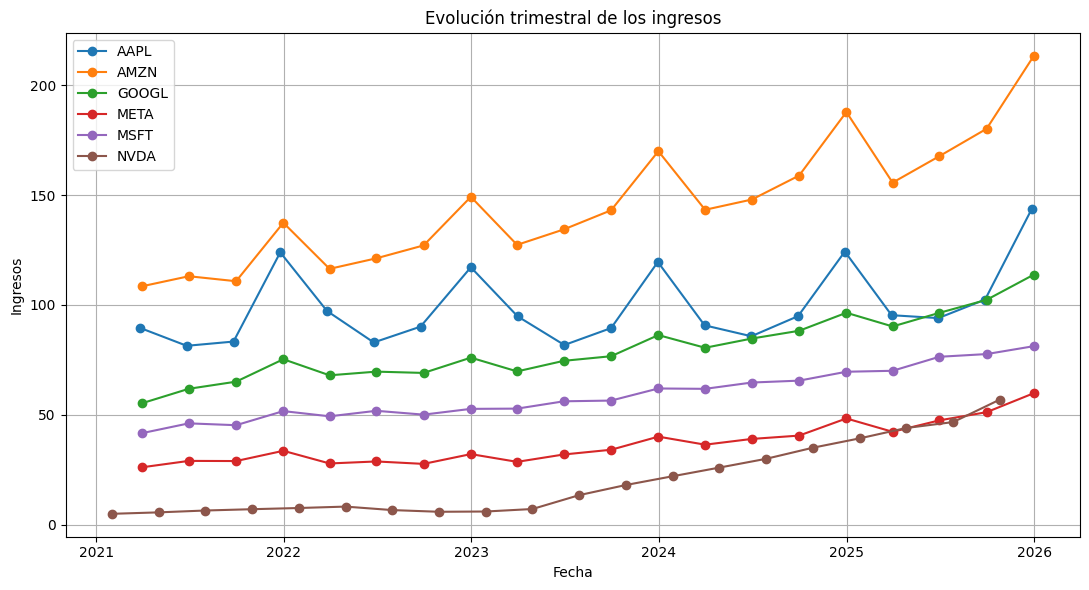

In [ ]:
plt.figure(figsize=(11, 6))

for empresa in panel["empresa"].unique():
    datos_empresa = panel[panel["empresa"] == empresa]
    plt.plot(
        datos_empresa["fecha"],
        datos_empresa["ingresos"],
        marker="o",
        label=empresa
    )

plt.title("Evolución trimestral de los ingresos")
plt.xlabel("Fecha")
plt.ylabel("Ingresos")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 8. Comportamiento de Apple a través del tiempo

En esta parte voy a revisar el comportamiento histórico del precio de Apple y de sus rendimientos. La intención es identificar si la serie mantiene un comportamiento estable a lo largo del tiempo antes de utilizar modelos de pronóstico.

Al aplicar la prueba ADF encontré una diferencia clara entre el precio de Apple y sus rendimientos.

El precio obtuvo un p-value cercano a 0.95, por lo que no se puede considerar una serie estacionaria. En cambio, los rendimientos obtuvieron un p-value prácticamente igual a cero, lo que indica que su comportamiento sí es estacionario.

Por esta razón, para los siguientes modelos utilizaré principalmente los rendimientos de Apple, ya que presentan un comportamiento más adecuado para trabajar con series de tiempo.

In [ ]:
from statsmodels.tsa.stattools import adfuller

# Serie de precios de Apple
precio_apple = precios["AAPL.O"]

# Rendimientos de Apple
rend_apple = rendimientos["AAPL.O"]

# Prueba ADF para el precio
adf_precio = adfuller(precio_apple)

# Prueba ADF para los rendimientos
adf_rend = adfuller(rend_apple)

print("ADF - Precio de Apple")
print("Estadístico:", adf_precio[0])
print("p-value:", adf_precio[1])

print("\nADF - Rendimientos de Apple")
print("Estadístico:", adf_rend[0])
print("p-value:", adf_rend[1])

ADF - Precio de Apple
Estadístico: -0.130319425992762
p-value: 0.9463336066345752

ADF - Rendimientos de Apple
Estadístico: -15.866402874066234
p-value: 9.087094447099891e-29


/tmp/ipykernel_2611/3547072486.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_precio = adfuller(precio_apple)
/tmp/ipykernel_2611/3547072486.py:13: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_rend = adfuller(rend_apple)


## 9. Relación de Apple con sus propios rendimientos pasados

En esta parte revisaré si los rendimientos de Apple presentan alguna relación con sus propios valores de días anteriores. La idea es identificar si existe cierta persistencia en el comportamiento de la serie.

In [ ]:
from statsmodels.tsa.ar_model import AutoReg

# Ajustar un modelo autorregresivo usando 5 rezagos
modelo_ar = AutoReg(rend_apple, lags=5).fit()

# Resultados
modelo_ar.summary()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


<class 'statsmodels.iolib.summary.Summary'>
"""
                            AutoReg Model Results                             
==============================================================================
Dep. Variable:                 AAPL.O   No. Observations:                  994
Model:                     AutoReg(5)   Log Likelihood                2686.453
Method:               Conditional MLE   S.D. of innovations              0.016
Date:                Sun, 08 Nov 2026   AIC                          -5358.906
Time:                        01:41:33   BIC                          -5324.594
Sample:                             5   HQIC                         -5345.861
                                  999                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0009      0.001      1.744      0.081      -0.000       0.002
AAPL.O.L1      0.0348      0.032      1.098      0.272      -0.027       0.097
AAPL.O.L2      0.0370      0.032      1.168      0.243      -0.025       0.099
AAPL.O.L3     -0.0473      0.032     -1.489      0.137      -0.110       0.015
AAPL.O.L4     -0.0627      0.032     -1.970      0.049      -0.125      -0.000
AAPL.O.L5     -0.0621      0.032     -1.947      0.051      -0.125       0.000
                                    Roots                                    
=============================================================================
                  Real          Imaginary           Modulus         Frequency
-----------------------------------------------------------------------------
AR.1            1.1935           -0.9848j            1.5473           -0.1098
AR.2            1.1935           +0.9848j            1.5473            0.1098
AR.3           -1.8603           -0.0000j            1.8603           -0.5000
AR.4           -0.7682           -1.7400j            1.9021           -0.3162
AR.5           -0.7682           +1.7400j            1.9021            0.3162
-----------------------------------------------------------------------------
"""

Al revisar los últimos cinco rezagos de los rendimientos de Apple, la mayoría no resultaron estadísticamente significativos.

Solamente el cuarto rezago mostró una relación significativa al nivel de 5%, mientras que el quinto quedó muy cerca de ese nivel. En general, esto sugiere que los rendimientos pasados de Apple tienen una capacidad limitada para explicar por sí solos el rendimiento actual.

Por esta razón, considero que no sería suficiente depender únicamente de este modelo para realizar un pronóstico de corto plazo.

## 10. Pronóstico de corto plazo para Apple

Después de revisar el comportamiento de los rendimientos de Apple, ahora voy a utilizar modelos de series de tiempo para intentar generar un pronóstico de corto plazo.

La idea es comparar diferentes especificaciones y elegir una que pueda representar de forma razonable el comportamiento reciente de la serie.

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

# Probar algunas combinaciones sencillas de ARMA sobre los rendimientos
resultados_modelos = []

for p in range(0, 4):
    for q in range(0, 4):
        if p == 0 and q == 0:
            continue

        try:
            modelo = ARIMA(rend_apple, order=(p, 0, q)).fit()
            resultados_modelos.append({
                "p": p,
                "q": q,
                "AIC": modelo.aic,
                "BIC": modelo.bic
            })
        except:
            pass

comparacion_modelos = pd.DataFrame(resultados_modelos).sort_values("BIC")

comparacion_modelos.head(10)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, fr

,p,q,AIC,BIC
3,1,0,-5385.000724,-5370.280460
0,0,1,-5384.861473,-5370.141209
1,0,2,-5384.755121,-5365.128102
7,2,0,-5384.311908,-5364.684889
4,1,1,-5382.430014,-5362.802994
11,3,0,-5385.145754,-5360.611980
2,0,3,-5384.207416,-5359.673642
8,2,1,-5382.388214,-5357.854440
6,1,3,-5387.252389,-5357.811861
5,1,2,-5381.847200,-5357.313426


In [ ]:
# Comparar modelos ARIMA para el precio de Apple
resultados_arima = []

for p in range(0, 4):
    for q in range(0, 4):
        try:
            modelo = ARIMA(precio_apple, order=(p, 1, q)).fit()

            resultados_arima.append({
                "p": p,
                "d": 1,
                "q": q,
                "AIC": modelo.aic,
                "BIC": modelo.bic
            })
        except:
            pass

comparacion_arima = pd.DataFrame(resultados_arima).sort_values("BIC")

comparacion_arima.head(10)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, fr

,p,d,q,AIC,BIC
0,0,1,0,5431.169472,5436.076227
4,1,1,0,5431.149408,5440.962918
1,0,1,1,5431.273226,5441.086736
2,0,1,2,5431.878518,5446.598782
8,2,1,0,5432.278032,5446.998297
5,1,1,1,5432.920184,5447.640448
12,3,1,0,5431.187520,5450.814539
3,0,1,3,5432.028104,5451.655123
9,2,1,1,5432.403140,5452.030160
6,1,1,2,5433.289443,5452.916462


In [ ]:
# Quitar el índice de fechas para evitar el error
precio_apple_modelo = precio_apple.reset_index(drop=True)

# Modelo ARIMA seleccionado
modelo_final_arima = ARIMA(precio_apple_modelo, order=(0, 1, 0)).fit()

# Pronóstico de los próximos 5 periodos
pronostico = modelo_final_arima.get_forecast(steps=5)

forecast = pronostico.summary_frame()

forecast

AAPL.O,mean,mean_se,mean_ci_lower,mean_ci_upper
1000,342.37,3.663292,335.190080,349.549920
1001,342.37,5.180677,332.216059,352.523941
1002,342.37,6.345008,329.934013,354.805987
1003,342.37,7.326584,328.010159,356.729841
1004,342.37,8.191370,326.315210,358.424790


In [ ]:
# Fechas para los próximos 5 días hábiles
fechas_futuras = pd.bdate_range(start="2026-11-09", periods=5)

# Agregar las fechas al pronóstico
forecast.index = fechas_futuras

forecast

AAPL.O,mean,mean_se,mean_ci_lower,mean_ci_upper
2026-11-09,342.37,3.663292,335.190080,349.549920
2026-11-10,342.37,5.180677,332.216059,352.523941
2026-11-11,342.37,6.345008,329.934013,354.805987
2026-11-12,342.37,7.326584,328.010159,356.729841
2026-11-13,342.37,8.191370,326.315210,358.424790


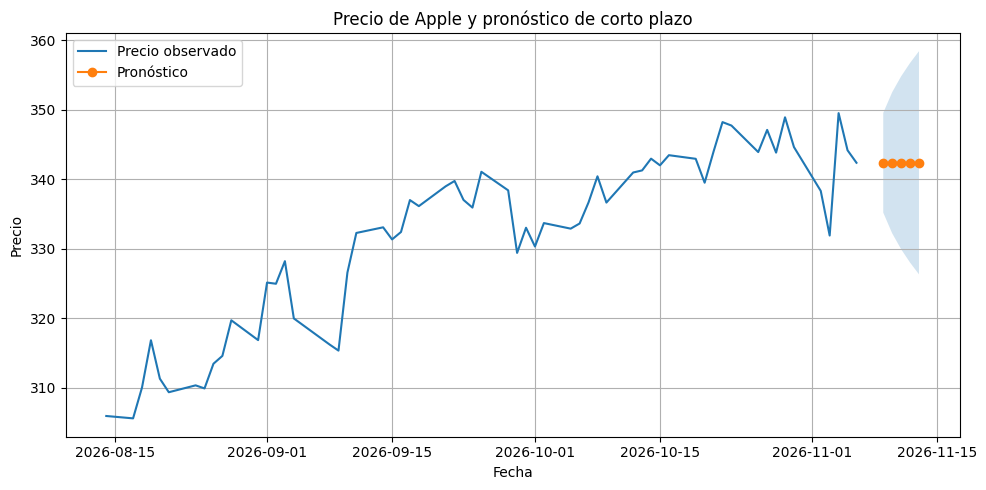

In [ ]:
# Gráfica del precio reciente de Apple y su pronóstico

plt.figure(figsize=(10, 5))

# Últimos 60 días observados
plt.plot(
    precio_apple.tail(60).index,
    precio_apple.tail(60).values,
    label="Precio observado"
)

# Pronóstico
plt.plot(
    forecast.index,
    forecast["mean"],
    marker="o",
    label="Pronóstico"
)

# Intervalo de confianza
plt.fill_between(
    forecast.index,
    forecast["mean_ci_lower"],
    forecast["mean_ci_upper"],
    alpha=0.2
)

plt.title("Precio de Apple y pronóstico de corto plazo")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Después de probar distintas opciones, el modelo que mejor se ajustó fue un ARIMA(0,1,0). Con este modelo hice una estimación para los siguientes cinco días hábiles.

El resultado fue bastante estable, ya que el precio estimado se mantiene alrededor de 342.37 durante todo el periodo. Esto me hace pensar que, con la información histórica disponible, no se observa una señal clara de que el precio vaya a subir o bajar de forma importante en el corto plazo.

También se puede ver que el rango posible de resultados se va haciendo más amplio conforme avanzan los días. En otras palabras, mientras más lejos intento pronosticar, mayor es la incertidumbre.

Por eso, tomaría este resultado como una referencia adicional, pero no como una señal suficiente por sí sola para decidir una operación.

## 11. Volatilidad de Apple

Después de revisar el comportamiento del precio y realizar un pronóstico de corto plazo, ahora analizaré la volatilidad de Apple.

La intención es identificar qué tan variables han sido sus rendimientos y estimar si pueden esperarse movimientos más amplios en los siguientes periodos.

In [ ]:
!pip -q install arch

from arch import arch_model

# Rendimientos de Apple en porcentaje
rend_apple_pct = rend_apple * 100

# Modelo GARCH(1,1)
modelo_garch = arch_model(
    rend_apple_pct,
    vol="Garch",
    p=1,
    q=1,
    dist="t"
)

resultado_garch = modelo_garch.fit(disp="off")

resultado_garch.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                        Constant Mean - GARCH Model Results                         
====================================================================================
Dep. Variable:                       AAPL.O   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -1789.00
Distribution:      Standardized Student's t   AIC:                           3588.00
Method:                  Maximum Likelihood   BIC:                           3612.54
                                              No. Observations:                  999
Date:                      Sun, Nov 08 2026   Df Residuals:                      998
Time:                              02:01:39   Df Model:                            1
                                Mean Model                                
==========================================================================
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1026  4.294e-02      2.389  1.688e-02 [1.844e-02,  0.187]
                              Volatility Model                             
===========================================================================
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
omega          0.2055      0.355      0.579      0.563    [ -0.491,  0.902]
alpha[1]       0.0674  5.868e-02      1.149      0.251 [-4.759e-02,  0.182]
beta[1]        0.8565      0.185      4.621  3.812e-06    [  0.493,  1.220]
                              Distribution                              
========================================================================
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
nu             3.9988      0.531      7.537  4.808e-14 [  2.959,  5.039]
========================================================================

Covariance estimator: robust
"""

In [ ]:
# Pronóstico de volatilidad para los siguientes 5 días
pronostico_vol = resultado_garch.forecast(horizon=5)

# Varianza esperada
varianza_futura = pronostico_vol.variance.iloc[-1]

# Convertir varianza a volatilidad
volatilidad_futura = np.sqrt(varianza_futura)

volatilidad_futura

,2026-11-06
h.1,1.854159
h.2,1.838961
h.3,1.824807
h.4,1.811632
h.5,1.799374


El modelo GARCH muestra una volatilidad esperada cercana a 1.8% diario para los próximos periodos.

El resultado disminuye ligeramente conforme avanza el horizonte, pasando de aproximadamente 1.85% en el primer periodo a 1.80% en el quinto. Esto sugiere que el modelo no está anticipando un incremento importante en la volatilidad de Apple en el corto plazo.

En conjunto, el resultado me sirve para tener una referencia del tamaño de los movimientos que podrían presentarse, aunque no indica directamente si el precio se moverá hacia arriba o hacia abajo.

## 12. Distribución del portafolio

Después de analizar las acciones de forma individual, ahora voy a revisar cómo se comportan en conjunto dentro de un portafolio.

La intención es buscar una distribución entre las 10 acciones que permita reducir el riesgo total, tomando en cuenta tanto la volatilidad de cada acción como la relación que existe entre ellas.

In [ ]:
from scipy.optimize import minimize

# Matriz de covarianzas de los rendimientos
covarianzas = rendimientos.cov()

# Número de acciones
n = len(covarianzas.columns)

# Función para calcular el riesgo del portafolio
def riesgo_portafolio(pesos):
    return np.sqrt(np.dot(pesos.T, np.dot(covarianzas, pesos)))

# Empezar suponiendo el mismo peso para todas las acciones
pesos_iniciales = np.repeat(1 / n, n)

# Los pesos deben sumar 100%
restricciones = ({
    "type": "eq",
    "fun": lambda pesos: np.sum(pesos) - 1
})

# No permitir posiciones negativas
limites = tuple((0, 1) for _ in range(n))

# Buscar la combinación de menor riesgo
resultado_min_var = minimize(
    riesgo_portafolio,
    pesos_iniciales,
    method="SLSQP",
    bounds=limites,
    constraints=restricciones
)

# Mostrar los pesos obtenidos
pesos_min_var = pd.Series(
    resultado_min_var.x,
    index=covarianzas.columns
)

pesos_min_var.sort_values(ascending=False)

,0
XOM,2.077376e-01
MSFT.O,1.891087e-01
CVX,1.620151e-01
JPM,1.446940e-01
AAPL.O,1.256859e-01
GOOGL.O,1.065569e-01
BAC,6.420181e-02
NVDA.O,7.806256e-18
AMZN.O,3.469447e-18
META.O,4.336809e-19


In [ ]:
# Riesgo diario del portafolio de mínima varianza
riesgo_diario = riesgo_portafolio(resultado_min_var.x)

# Convertir a volatilidad anual aproximada
riesgo_anual = riesgo_diario * np.sqrt(252)

print("Volatilidad diaria:", round(riesgo_diario * 100, 2), "%")
print("Volatilidad anual aproximada:", round(riesgo_anual * 100, 2), "%")

Volatilidad diaria: 0.96 %
Volatilidad anual aproximada: 15.2 %


## 13. Riesgo del portafolio y VaR

In [ ]:
from scipy.stats import norm

# Nivel de confianza
confianza = 0.95

# VaR diario paramétrico
z = norm.ppf(confianza)

var_95 = z * riesgo_diario

print("VaR diario al 95%:", round(var_95 * 100, 2), "%")

VaR diario al 95%: 1.57 %


La combinación de mínima varianza dio como resultado una volatilidad diaria cercana a 0.96% y una volatilidad anual aproximada de 15.2%.

También calculé un VaR diario al 95% de aproximadamente 1.57%. Bajo los supuestos del modelo, esto indica que existe aproximadamente un 5% de probabilidad de observar una pérdida diaria superior a ese nivel.

Para mí, este resultado sirve como una referencia sencilla del riesgo del portafolio y permite comparar si la distribución seleccionada realmente ayuda a reducir la exposición frente a tener posiciones más concentradas.

## 14. Selección de acciones para la estrategia

Ahora voy a revisar cuáles de las acciones del portafolio pueden resultar más interesantes para seguir durante la siguientes jornadas bursatiles.

Para hacerlo, voy a comparar su comportamiento reciente, tomando en cuenta el rendimiento de los últimos días y qué tan volátiles han estado. La idea es quedarme con unas cuantas opciones para darles seguimiento más de cerca antes de realizar las operaciones simuladas.

In [ ]:
# Cambios recientes de cada acción
retorno_5d = precios.pct_change(5).iloc[-1]
retorno_20d = precios.pct_change(20).iloc[-1]

# Volatilidad de los últimos 20 días
vol_20d = rendimientos.tail(20).std()

# Tabla para comparar las acciones
seleccion_trading = pd.DataFrame({
    "Retorno 5 días": retorno_5d,
    "Retorno 20 días": retorno_20d,
    "Volatilidad 20 días": vol_20d
})

# Mostrar en porcentaje
seleccion_trading = seleccion_trading * 100

seleccion_trading.sort_values("Retorno 20 días", ascending=False)

,Retorno 5 días,Retorno 20 días,Volatilidad 20 días
AAPL.O,-0.655776,1.702115,1.612131
JPM,-0.756587,0.450464,1.693409
CVX,-9.727412,0.297198,1.797615
MSFT.O,1.666954,-0.833536,2.206322
AMZN.O,7.884335,-1.192699,2.590866
XOM,-11.417891,-1.817213,2.089771
BAC,-1.179764,-9.020619,1.807660
META.O,-0.787005,-15.100115,2.580381
NVDA.O,-8.795934,-18.597348,3.010182
GOOGL.O,1.765294,-19.018370,3.315643


## 15. Reglas para la sesión de trading

Para la simulación de trading voy a dar seguimiento principalmente a Apple, Microsoft y Amazon, ya que mostraron comportamientos recientes distintos y pueden servir para comparar diferentes escenarios durante la sesión.

La idea será esperar los primeros minutos después de la apertura antes de realizar alguna operación. Después revisaré el comportamiento del precio y utilizaré algunos indicadores de corto plazo como apoyo para decidir si existe una señal suficientemente clara para entrar.

No necesariamente voy a operar las tres acciones. La intención es realizar solamente las operaciones donde se cumplan las condiciones que definí previamente y llevar un registro de la entrada, salida y resultado obtenido.

## 16. Señales para las operaciones

Para facilitar el seguimiento durante la sesión, voy a utilizar algunas reglas sencillas que me permitan identificar posibles momentos de entrada.

La intención es combinar el comportamiento del precio con indicadores de corto plazo como VWAP, medias móviles y RSI. Esto me permitirá tener una referencia más objetiva antes de decidir si realizo alguna de las operaciones simuladas.

In [ ]:
def evaluar_senal(datos):
    datos = calcular_senales(datos)

    ultima = datos.iloc[-1]

    condiciones_largo = {
        "Precio sobre VWAP": ultima["Close"] > ultima["VWAP"],
        "EMA9 sobre EMA20": ultima["EMA9"] > ultima["EMA20"],
        "RSI entre 50 y 70": 50 < ultima["RSI"] < 70,
        "MACD sobre señal": ultima["MACD"] > ultima["MACD_signal"]
    }

    condiciones_corto = {
        "Precio bajo VWAP": ultima["Close"] < ultima["VWAP"],
        "EMA9 bajo EMA20": ultima["EMA9"] < ultima["EMA20"],
        "RSI entre 30 y 50": 30 < ultima["RSI"] < 50,
        "MACD bajo señal": ultima["MACD"] < ultima["MACD_signal"]
    }

    total_largo = sum(condiciones_largo.values())
    total_corto = sum(condiciones_corto.values())

    if total_largo == 4:
        señal = "LARGO - SEÑAL FUERTE"
        condiciones = condiciones_largo

    elif total_corto == 4:
        señal = "CORTO - SEÑAL FUERTE"
        condiciones = condiciones_corto

    elif total_largo == 3:
        señal = "LARGO - SEÑAL MODERADA"
        condiciones = condiciones_largo

    elif total_corto == 3:
        señal = "CORTO - SEÑAL MODERADA"
        condiciones = condiciones_corto

    else:
        señal = "SIN SEÑAL"
        condiciones = {}

    return señal, condiciones

In [ ]:
# Datos de ejemplo para probar el sistema
fechas_prueba = pd.date_range("2026-11-09 08:30", periods=40, freq="5min")

datos_prueba = pd.DataFrame({
    "Close": np.linspace(100, 104, 40) + np.random.normal(0, 0.15, 40),
    "High": np.linspace(100.2, 104.2, 40) + np.random.normal(0, 0.10, 40),
    "Low": np.linspace(99.8, 103.8, 40) + np.random.normal(0, 0.10, 40),
    "Volume": np.random.randint(1000, 5000, 40)
}, index=fechas_prueba)

senal_prueba, condiciones_prueba = evaluar_senal(datos_prueba)

print("Resultado:", senal_prueba)
print("\nCondiciones:")
for nombre, cumple in condiciones_prueba.items():
    print(nombre, ":", cumple)

Resultado: LARGO - SEÑAL FUERTE

Condiciones:
Precio sobre VWAP : True
EMA9 sobre EMA20 : True
RSI mayor a 50 : True
MACD sobre señal : True


In [ ]:
# Datos de ejemplo para probar una señal bajista
fechas_bajista = pd.date_range("2026-11-09 08:30", periods=40, freq="5min")

datos_bajista = pd.DataFrame({
    "Close": np.linspace(104, 100, 40) + np.random.normal(0, 0.15, 40),
    "High": np.linspace(104.2, 100.2, 40) + np.random.normal(0, 0.10, 40),
    "Low": np.linspace(103.8, 99.8, 40) + np.random.normal(0, 0.10, 40),
    "Volume": np.random.randint(1000, 5000, 40)
}, index=fechas_bajista)

senal_bajista, condiciones_bajista = evaluar_senal(datos_bajista)

print("Resultado:", senal_bajista)
print("\nCondiciones:")
for nombre, cumple in condiciones_bajista.items():
    print(nombre, ":", cumple)

Resultado: CORTO - SEÑAL FUERTE

Condiciones:
Precio bajo VWAP : True
EMA9 bajo EMA20 : True
RSI menor a 50 : True
MACD bajo señal : True


In [ ]:
def calcular_operacion(precio_entrada, señal):
    riesgo = 0.005       # 0.5%
    objetivo = 0.01      # 1.0%

    if "LARGO" in señal:
        stop_loss = precio_entrada * (1 - riesgo)
        take_profit = precio_entrada * (1 + objetivo)

    elif "CORTO" in señal:
        stop_loss = precio_entrada * (1 + riesgo)
        take_profit = precio_entrada * (1 - objetivo)

    else:
        return "No hay operación"

    return {
        "Entrada": round(precio_entrada, 2),
        "Stop Loss": round(stop_loss, 2),
        "Take Profit": round(take_profit, 2)
    }

In [ ]:
calcular_operacion(100, "LARGO - SEÑAL FUERTE")

{'Entrada': 100, 'Stop Loss': 99.5, 'Take Profit': 101.0}

In [ ]:
print("Prueba LARGO:")
print(calcular_operacion(100, "LARGO - SEÑAL FUERTE"))

print("\nPrueba CORTO:")
print(calcular_operacion(100, "CORTO - SEÑAL FUERTE"))

Prueba LARGO:
{'Entrada': 100, 'Stop Loss': 99.5, 'Take Profit': 101.0}

Prueba CORTO:
{'Entrada': 100, 'Stop Loss': 100.5, 'Take Profit': 99.0}


In [ ]:
def analizar_operacion(datos):
    # Evaluar señal
    señal, condiciones = evaluar_senal(datos)

    # Último precio disponible
    precio_actual = datos["Close"].iloc[-1]

    # Si no hay señal fuerte, no operar
    if "SEÑAL FUERTE" not in señal:
        return {
            "Señal": señal,
            "Operación": "NO OPERAR",
            "Condiciones": condiciones
        }

    # Si hay señal fuerte, calcular niveles de operación
    operacion = calcular_operacion(precio_actual, señal)

    resultado = {
        "Señal": señal,
        "Operación": "OPERAR",
        "Entrada": operacion["Entrada"],
        "Stop Loss": operacion["Stop Loss"],
        "Take Profit": operacion["Take Profit"],
        "Condiciones": condiciones
    }

    return resultado

In [ ]:
print("PRUEBA ALCISTA")
resultado_alcista = analizar_operacion(datos_prueba)
print(resultado_alcista)

print("\nPRUEBA BAJISTA")
resultado_bajista = analizar_operacion(datos_bajista)
print(resultado_bajista)

PRUEBA ALCISTA
{'Señal': 'LARGO - SEÑAL FUERTE', 'Operación': 'OPERAR', 'Entrada': np.float64(104.07), 'Stop Loss': np.float64(103.55), 'Take Profit': np.float64(105.11), 'Condiciones': {'Precio sobre VWAP': np.True_, 'EMA9 sobre EMA20': np.True_, 'RSI mayor a 50': np.True_, 'MACD sobre señal': np.True_}}

PRUEBA BAJISTA
{'Señal': 'CORTO - SEÑAL FUERTE', 'Operación': 'OPERAR', 'Entrada': np.float64(99.83), 'Stop Loss': np.float64(100.33), 'Take Profit': np.float64(98.84), 'Condiciones': {'Precio bajo VWAP': np.True_, 'EMA9 bajo EMA20': np.True_, 'RSI menor a 50': np.True_, 'MACD bajo señal': np.True_}}


In [ ]:
import pandas as pd
import numpy as np

In [ ]:
!pip -q install yfinance

In [ ]:
import yfinance as yf

In [ ]:
datos_aapl = yf.download(
    "AAPL",
    period="5d",
    interval="5m",
    auto_adjust=False,
    progress=False
)

datos_aapl.tail()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Datetime,,,,,,
2026-11-06 20:35:00+00:00,343.714996,343.714996,343.869995,343.640015,343.845001,270177
2026-11-06 20:40:00+00:00,343.484985,343.484985,343.704987,343.290009,343.700012,294956
2026-11-06 20:45:00+00:00,343.250000,343.250000,343.619995,343.089996,343.459991,343518
2026-11-06 20:50:00+00:00,342.510010,342.510010,343.630005,342.130005,343.329987,692154
2026-11-06 20:55:00+00:00,342.364990,342.364990,343.070007,342.260010,342.855011,1463728


In [ ]:
# Simplificar las columnas de los datos de Apple
datos_aapl.columns = datos_aapl.columns.get_level_values(0)

print(datos_aapl.columns)
datos_aapl.tail()

Index(['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='object', name='Price')


Price,Adj Close,Close,High,Low,Open,Volume
Datetime,,,,,,
2026-11-06 20:35:00+00:00,343.714996,343.714996,343.869995,343.640015,343.845001,270177
2026-11-06 20:40:00+00:00,343.484985,343.484985,343.704987,343.290009,343.700012,294956
2026-11-06 20:45:00+00:00,343.250000,343.250000,343.619995,343.089996,343.459991,343518
2026-11-06 20:50:00+00:00,342.510010,342.510010,343.630005,342.130005,343.329987,692154
2026-11-06 20:55:00+00:00,342.364990,342.364990,343.070007,342.260010,342.855011,1463728


In [ ]:
resultado_aapl = analizar_operacion(datos_aapl)

print("ANÁLISIS AAPL")
print(resultado_aapl)

ANÁLISIS AAPL
{'Señal': 'CORTO - SEÑAL FUERTE', 'Operación': 'OPERAR', 'Entrada': np.float64(342.36), 'Stop Loss': np.float64(344.08), 'Take Profit': np.float64(338.94), 'Condiciones': {'Precio bajo VWAP': np.True_, 'EMA9 bajo EMA20': np.True_, 'RSI menor a 50': np.True_, 'MACD bajo señal': np.True_}}


In [ ]:
def calcular_senales(datos):
    datos = datos.copy()

    # Medias móviles exponenciales
    datos["EMA9"] = datos["Close"].ewm(span=9, adjust=False).mean()
    datos["EMA20"] = datos["Close"].ewm(span=20, adjust=False).mean()

    # VWAP intradía: se reinicia en cada sesión
    precio_tipico = (datos["High"] + datos["Low"] + datos["Close"]) / 3
    fecha_sesion = pd.Series(datos.index.date, index=datos.index)

    volumen_acumulado = datos["Volume"].groupby(fecha_sesion).cumsum()
    precio_volumen_acumulado = (
        (precio_tipico * datos["Volume"])
        .groupby(fecha_sesion)
        .cumsum()
    )

    datos["VWAP"] = precio_volumen_acumulado / volumen_acumulado

    # RSI de 14 periodos
    cambio = datos["Close"].diff()

    ganancias = cambio.clip(lower=0)
    perdidas = -cambio.clip(upper=0)

    media_ganancias = ganancias.rolling(14).mean()
    media_perdidas = perdidas.rolling(14).mean()

    rs = media_ganancias / media_perdidas
    datos["RSI"] = 100 - (100 / (1 + rs))

    # MACD
    ema12 = datos["Close"].ewm(span=12, adjust=False).mean()
    ema26 = datos["Close"].ewm(span=26, adjust=False).mean()

    datos["MACD"] = ema12 - ema26
    datos["MACD_signal"] = datos["MACD"].ewm(span=9, adjust=False).mean()

    return datos

In [ ]:
resultado_aapl = analizar_operacion(datos_aapl)

print("ANÁLISIS AAPL")
print(resultado_aapl)

ANÁLISIS AAPL
{'Señal': 'CORTO - SEÑAL FUERTE', 'Operación': 'OPERAR', 'Entrada': np.float64(342.36), 'Stop Loss': np.float64(344.08), 'Take Profit': np.float64(338.94), 'Condiciones': {'Precio bajo VWAP': np.True_, 'EMA9 bajo EMA20': np.True_, 'RSI menor a 50': np.True_, 'MACD bajo señal': np.True_}}


In [ ]:
datos_msft = yf.download(
    "MSFT",
    period="5d",
    interval="5m",
    auto_adjust=False,
    progress=False
)

datos_amzn = yf.download(
    "AMZN",
    period="5d",
    interval="5m",
    auto_adjust=False,
    progress=False
)

In [ ]:
datos_msft.columns = datos_msft.columns.get_level_values(0)
datos_amzn.columns = datos_amzn.columns.get_level_values(0)

In [ ]:
resultado_msft = analizar_operacion(datos_msft)
resultado_amzn = analizar_operacion(datos_amzn)

print("ANÁLISIS MSFT")
print(resultado_msft)

print("\nANÁLISIS AMZN")
print(resultado_amzn)

ANÁLISIS MSFT
{'Señal': 'CORTO - SEÑAL FUERTE', 'Operación': 'OPERAR', 'Entrada': np.float64(530.55), 'Stop Loss': np.float64(533.2), 'Take Profit': np.float64(525.24), 'Condiciones': {'Precio bajo VWAP': np.True_, 'EMA9 bajo EMA20': np.True_, 'RSI menor a 50': np.True_, 'MACD bajo señal': np.True_}}

ANÁLISIS AMZN
{'Señal': 'CORTO - SEÑAL FUERTE', 'Operación': 'OPERAR', 'Entrada': np.float64(259.35), 'Stop Loss': np.float64(260.65), 'Take Profit': np.float64(256.76), 'Condiciones': {'Precio bajo VWAP': np.True_, 'EMA9 bajo EMA20': np.True_, 'RSI menor a 50': np.True_, 'MACD bajo señal': np.True_}}


In [ ]:
resumen = pd.DataFrame([
    {
        "Ticker": "AAPL",
        "Señal": resultado_aapl["Señal"],
        "Operación": resultado_aapl["Operación"],
        "Entrada": resultado_aapl.get("Entrada"),
        "Stop Loss": resultado_aapl.get("Stop Loss"),
        "Take Profit": resultado_aapl.get("Take Profit")
    },
    {
        "Ticker": "MSFT",
        "Señal": resultado_msft["Señal"],
        "Operación": resultado_msft["Operación"],
        "Entrada": resultado_msft.get("Entrada"),
        "Stop Loss": resultado_msft.get("Stop Loss"),
        "Take Profit": resultado_msft.get("Take Profit")
    },
    {
        "Ticker": "AMZN",
        "Señal": resultado_amzn["Señal"],
        "Operación": resultado_amzn["Operación"],
        "Entrada": resultado_amzn.get("Entrada"),
        "Stop Loss": resultado_amzn.get("Stop Loss"),
        "Take Profit": resultado_amzn.get("Take Profit")
    }
])

resumen

,Ticker,Señal,Operación,Entrada,Stop Loss,Take Profit
0,AAPL,CORTO - SEÑAL FUERTE,OPERAR,342.36,344.08,338.94
1,MSFT,CORTO - SEÑAL FUERTE,OPERAR,530.55,533.20,525.24
2,AMZN,CORTO - SEÑAL FUERTE,OPERAR,259.35,260.65,256.76


In [ ]:
def analizar_tickers(tickers):
    resultados = []

    for ticker in tickers:

        # Descargar datos intradía
        datos = yf.download(
            ticker,
            period="5d",
            interval="5m",
            auto_adjust=False,
            progress=False
        )

        # Simplificar columnas
        datos.columns = datos.columns.get_level_values(0)

        # Analizar la operación
        resultado = analizar_operacion(datos)

        # Guardar resultado en formato de tabla
        resultados.append({
            "Ticker": ticker,
            "Señal": resultado["Señal"],
            "Operación": resultado["Operación"],
            "Entrada": resultado.get("Entrada"),
            "Stop Loss": resultado.get("Stop Loss"),
            "Take Profit": resultado.get("Take Profit")
        })

    return pd.DataFrame(resultados)

In [ ]:
tickers_seguimiento = ["AAPL", "MSFT", "AMZN"]

panel_trading = analizar_tickers(tickers_seguimiento)

panel_trading

,Ticker,Señal,Operación,Entrada,Stop Loss,Take Profit
0,AAPL,CORTO - SEÑAL FUERTE,OPERAR,342.36,344.08,338.94
1,MSFT,CORTO - SEÑAL FUERTE,OPERAR,530.55,533.20,525.24
2,AMZN,CORTO - SEÑAL FUERTE,OPERAR,259.35,260.65,256.76


In [ ]:
def analizar_ticker_detalle(ticker):
    # Descargar datos intradía de 5 minutos
    datos = yf.download(
        ticker,
        period="5d",
        interval="5m",
        auto_adjust=False,
        progress=False
    )

    # Simplificar columnas
    datos.columns = datos.columns.get_level_values(0)

    # Calcular indicadores técnicos
    datos_indicadores = calcular_senales(datos)

    # Evaluar señal
    señal, condiciones = evaluar_senal(datos)

    # Tomar la última vela disponible
    ultima = datos_indicadores.iloc[-1]

    # Contar cuántas condiciones se cumplen
    total_condiciones = sum(condiciones.values()) if condiciones else 0

    # Calcular entrada, stop y objetivo solo si hay señal fuerte
    resultado = analizar_operacion(datos)

    # Convertir la última vela al horario de Monterrey
    ultima_vela_mty = (
        datos_indicadores.index[-1]
        .tz_convert("America/Monterrey")
    )

    # Revisar si los datos corresponden al día actual
    fecha_hoy = pd.Timestamp.now(
        tz="America/Monterrey"
    ).date()

    estado_datos = (
        "ACTUAL"
        if ultima_vela_mty.date() == fecha_hoy
        else "DESACTUALIZADO"
    )

    # Revisar si estamos dentro de la ventana permitida para abrir operaciones
    hora_actual = pd.Timestamp.now(
        tz="America/Monterrey"
    ).time()

    inicio_operacion = pd.Timestamp("08:45").time()
    fin_operacion = pd.Timestamp("14:45").time()

    ventana_operativa = (
        "HABILITADA"
        if inicio_operacion <= hora_actual <= fin_operacion
        else "NO HABILITADA"
    )

    # Resultado final para el panel
    return {
        "Ticker": ticker,
        "Señal": resultado["Señal"],
        "Operación": resultado["Operación"],
        "Condiciones": f"{total_condiciones}/4",
        "Última vela": ultima_vela_mty,
        "Estado datos": estado_datos,
        "Ventana operativa": ventana_operativa,
        "Precio": round(float(ultima["Close"]), 2),
        "VWAP": round(float(ultima["VWAP"]), 2),
        "EMA9": round(float(ultima["EMA9"]), 2),
        "EMA20": round(float(ultima["EMA20"]), 2),
        "RSI": round(float(ultima["RSI"]), 2),
        "MACD": round(float(ultima["MACD"]), 3),
        "MACD Señal": round(float(ultima["MACD_signal"]), 3),
        "Stop Loss": resultado.get("Stop Loss"),
        "Take Profit": resultado.get("Take Profit")
    }

In [ ]:
tickers_detalle = ["AAPL", "MSFT", "AMZN"]

panel_detalle = pd.DataFrame(
    [analizar_ticker_detalle(ticker) for ticker in tickers_detalle]
)

panel_detalle

,Ticker,Señal,Operación,Condiciones,Última vela,Estado datos,Ventana operativa,Precio,VWAP,EMA9,EMA20,RSI,MACD,MACD Señal,Stop Loss,Take Profit
0,AAPL,CORTO - SEÑAL FUERTE,OPERAR,4/4,2026-11-06 14:55:00-06:00,DESACTUALIZADO,NO HABILITADA,342.36,342.98,343.17,343.50,30.80,-0.316,-0.198,344.08,338.94
1,MSFT,CORTO - SEÑAL FUERTE,OPERAR,4/4,2026-11-06 14:55:00-06:00,DESACTUALIZADO,NO HABILITADA,530.55,533.33,531.59,532.13,37.01,-0.589,-0.476,533.20,525.24
2,AMZN,CORTO - SEÑAL MODERADA,NO OPERAR,3/4,2026-11-06 14:55:00-06:00,DESACTUALIZADO,NO HABILITADA,259.35,261.86,260.33,260.96,24.69,-0.613,-0.409,NaN,NaN


In [ ]:
import pandas as pd
import numpy as np
import yfinance as yf

In [ ]:
registro_operaciones = pd.DataFrame(columns=[
    "Fecha",
    "Hora entrada",
    "Ticker",
    "Dirección",
    "Señal",
    "Entrada",
    "Stop Loss",
    "Take Profit",
    "Hora salida",
    "Precio salida",
    "Resultado USD",
    "Resultado %",
    "Motivo salida",
    "Observaciones"
])

registro_operaciones

,Fecha,Hora entrada,Ticker,Dirección,Señal,Entrada,Stop Loss,Take Profit,Hora salida,Precio salida,Resultado USD,Resultado %,Motivo salida,Observaciones


In [ ]:
def registrar_entrada(
    ticker,
    señal,
    cantidad,
    entrada,
    stop_loss,
    take_profit,
    observaciones=""
):
    global registro_operaciones

    ahora = pd.Timestamp.now(tz="America/Monterrey")

    direccion = (
        "LARGO"
        if "LARGO" in señal
        else "CORTO"
    )

    nueva_operacion = {
        "Fecha": ahora.date(),
        "Hora entrada": ahora.strftime("%H:%M:%S"),
        "Ticker": ticker,
        "Dirección": direccion,
        "Señal": señal,
        "Cantidad": cantidad,
        "Entrada": entrada,
        "Stop Loss": stop_loss,
        "Take Profit": take_profit,
        "Hora salida": None,
        "Precio salida": None,
        "Resultado USD": None,
        "Resultado %": None,
        "Motivo salida": None,
        "Observaciones": observaciones
    }

    nueva_fila = pd.DataFrame([nueva_operacion])

    if registro_operaciones.empty:
        registro_operaciones = nueva_fila
    else:
        registro_operaciones = pd.concat(
            [registro_operaciones, nueva_fila],
            ignore_index=True
        )

    return registro_operaciones

In [ ]:
registro_operaciones = pd.DataFrame(columns=[
    "Fecha",
    "Hora entrada",
    "Ticker",
    "Dirección",
    "Señal",
    "Cantidad",
    "Entrada",
    "Stop Loss",
    "Take Profit",
    "Hora salida",
    "Precio salida",
    "Resultado USD",
    "Resultado %",
    "Motivo salida",
    "Observaciones"
])

registro_operaciones

,Fecha,Hora entrada,Ticker,Dirección,Señal,Cantidad,Entrada,Stop Loss,Take Profit,Hora salida,Precio salida,Resultado USD,Resultado %,Motivo salida,Observaciones


In [ ]:
def registrar_salida(indice, precio_salida, motivo_salida=""):
    global registro_operaciones

    ahora = pd.Timestamp.now(tz="America/Monterrey")

    direccion = registro_operaciones.loc[indice, "Dirección"]
    cantidad = registro_operaciones.loc[indice, "Cantidad"]
    entrada = registro_operaciones.loc[indice, "Entrada"]

    if direccion == "LARGO":
        resultado_usd = (precio_salida - entrada) * cantidad
        resultado_pct = ((precio_salida / entrada) - 1) * 100

    elif direccion == "CORTO":
        resultado_usd = (entrada - precio_salida) * cantidad
        resultado_pct = ((entrada / precio_salida) - 1) * 100

    else:
        return "Dirección no válida"

    registro_operaciones.loc[indice, "Hora salida"] = ahora.strftime("%H:%M:%S")
    registro_operaciones.loc[indice, "Precio salida"] = round(precio_salida, 2)
    registro_operaciones.loc[indice, "Resultado USD"] = round(resultado_usd, 2)
    registro_operaciones.loc[indice, "Resultado %"] = round(resultado_pct, 2)
    registro_operaciones.loc[indice, "Motivo salida"] = motivo_salida

    return registro_operaciones

In [ ]:
# Copia temporal para probar entrada y salida
registro_real = registro_operaciones.copy()

# Registrar entrada de prueba
registrar_entrada(
    ticker="AAPL",
    señal="CORTO - SEÑAL FUERTE",
    cantidad=10,
    entrada=342.36,
    stop_loss=344.08,
    take_profit=338.94,
    observaciones="Prueba completa del sistema"
)

# Cerrar la operación de prueba
registrar_salida(
    indice=0,
    precio_salida=340.00,
    motivo_salida="Prueba manual"
)

registro_operaciones

,Fecha,Hora entrada,Ticker,Dirección,Señal,Cantidad,Entrada,Stop Loss,Take Profit,Hora salida,Precio salida,Resultado USD,Resultado %,Motivo salida,Observaciones
0,2026-11-08,00:16:55,AAPL,CORTO,CORTO - SEÑAL FUERTE,10,342.36,344.08,338.94,00:16:55,340.0,23.6,0.69,Prueba manual,Prueba completa del sistema


In [ ]:
registro_operaciones = registro_real.copy()

registro_operaciones

,Fecha,Hora entrada,Ticker,Dirección,Señal,Cantidad,Entrada,Stop Loss,Take Profit,Hora salida,Precio salida,Resultado USD,Resultado %,Motivo salida,Observaciones


## 17. Metodología de la estrategia de trading

Para esta simulación de trading se utilizarán datos intradía en intervalos de cinco minutos y se dará seguimiento principalmente a Apple, Microsoft y Amazon.

La estrategia considera cuatro indicadores técnicos de corto plazo: VWAP, medias móviles exponenciales de 9 y 20 periodos, RSI y MACD. La intención es utilizar estos indicadores como filtros para identificar posibles señales alcistas o bajistas.

Para una señal larga se requiere que el precio se encuentre por encima del VWAP, la EMA de 9 periodos esté por encima de la EMA de 20 periodos, el RSI se encuentre entre 50 y 70 y el MACD esté por encima de su línea de señal.

Para una señal corta se utilizan las condiciones opuestas: precio por debajo del VWAP, EMA de 9 periodos por debajo de la EMA de 20 periodos, RSI entre 30 y 50 y MACD por debajo de su línea de señal.

Cuando se cumplen las cuatro condiciones se considera una señal fuerte. Si únicamente se cumplen tres, la señal se considera moderada y no se ejecuta automáticamente una operación.

También se definieron reglas adicionales de control. No se realizarán operaciones durante los primeros 15 minutos después de la apertura del mercado y no se abrirán nuevas posiciones después de las 14:45 horas de Monterrey.

En caso de realizar una operación, se utilizará inicialmente un stop loss equivalente a 0.5% del precio de entrada y un objetivo de utilidad de 1.0%, manteniendo una relación aproximada de riesgo-rendimiento de 1:2.

Las operaciones se realizarán en un entorno de simulación o paper trading y posteriormente se documentarán los resultados obtenidos.